In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
countries = {
    "MYS": "Malaysia",
    "SGP": "Singapore",
    "IDN": "Indonesia",
    "THA": "Thailand",
    "VNM": "Vietnam"
}

indicators = {
    "NY.GDP.MKTP.KD.ZG": "GDP_Growth",
    "FP.CPI.TOTL.ZG": "Inflation",
    "SL.UEM.TOTL.ZS": "Unemployment",
    "PA.NUS.FCRF": "Exchange_Rate",
    "BX.KLT.DINV.WD.GD.ZS": "FDI"
}

start_year = 2000
end_year = 2024

In [4]:
def get_world_bank_data(country_codes, indicator_code):

    countries_string = ";".join(country_codes)

    url = (
        f"https://api.worldbank.org/v2/country/"
        f"{countries_string}/indicator/{indicator_code}"
    )

    params = {
        "format": "json",
        "date": f"{start_year}:{end_year}",
        "per_page": 20000
    }

    response = requests.get(url, params=params)
    response.raise_for_status()

    results = response.json()

    if len(results) < 2 or results[1] is None:
        return pd.DataFrame()

    records = []

    for item in results[1]:

        records.append({
            "Country": item["country"]["value"],
            "Country_Code": item["countryiso3code"],
            "Year": int(item["date"]),
            "Value": item["value"]
        })

    return pd.DataFrame(records)

In [5]:
all_data = []

for indicator_code, indicator_name in indicators.items():

    df = get_world_bank_data(
        list(countries.keys()),
        indicator_code
    )

    if not df.empty:
        df["Indicator"] = indicator_name
        all_data.append(df)

raw_data = pd.concat(all_data, ignore_index=True)

print(raw_data.head())
print("Dataset shape:", raw_data.shape)

     Country Country_Code  Year     Value   Indicator
0  Indonesia          IDN  2024  5.032575  GDP_Growth
1  Indonesia          IDN  2023  5.048831  GDP_Growth
2  Indonesia          IDN  2022  5.307197  GDP_Growth
3  Indonesia          IDN  2021  3.702886  GDP_Growth
4  Indonesia          IDN  2020 -2.065512  GDP_Growth
Dataset shape: (625, 5)


In [6]:
# Check missing values
print(raw_data.isnull().sum())

# Check duplicate records
print("Duplicates:", raw_data.duplicated(
    subset=["Country_Code", "Year", "Indicator"]
).sum())

# Sort dataset
raw_data = raw_data.sort_values(
    by=["Country", "Year", "Indicator"]
)

# Save original retrieved data
raw_data.to_csv(
    "asean_macro_raw_data.csv",
    index=False
)

Country         0
Country_Code    0
Year            0
Value           0
Indicator       0
dtype: int64
Duplicates: 0


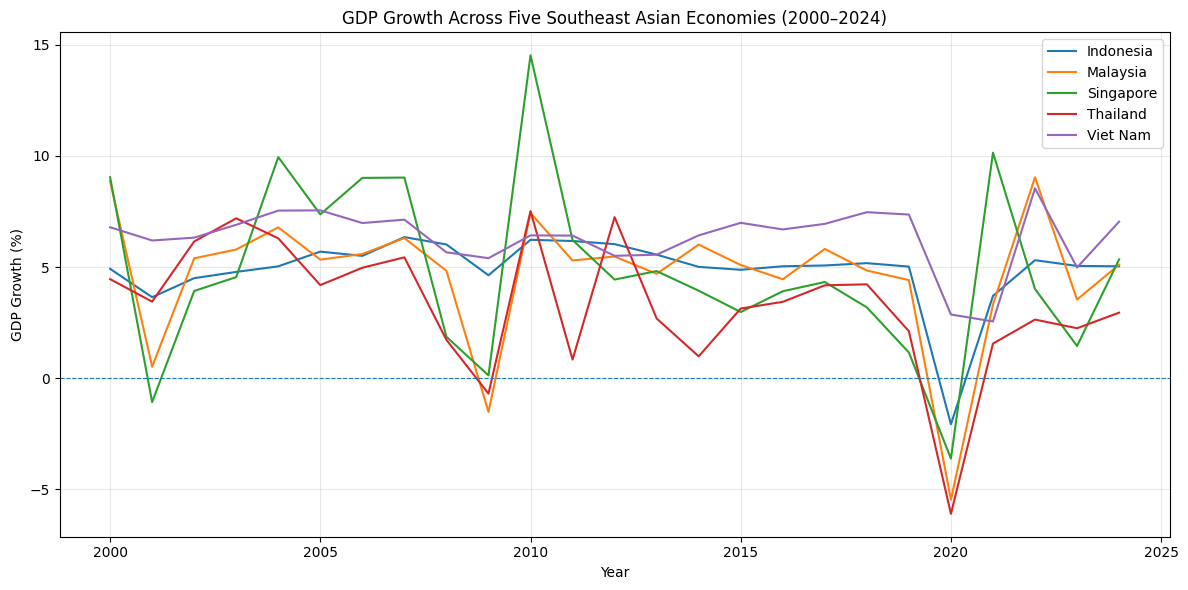

In [11]:
plt.figure(figsize=(12, 6))

for country in gdp_data["Country"].unique():

    country_data = gdp_data[
        gdp_data["Country"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["Value"],
        label=country
    )

plt.title("GDP Growth Across Five Southeast Asian Economies (2000–2024)")
plt.xlabel("Year")
plt.ylabel("GDP Growth (%)")
plt.axhline(y=0, linestyle="--", linewidth=0.8)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Display GDP growth for every country in 2020
gdp_2020 = gdp_data[
    gdp_data["Year"] == 2020
][["Country", "Value"]]

print(gdp_2020.sort_values("Value"))

       Country     Value
79    Thailand -6.093063
29    Malaysia -5.456847
54   Singapore -3.610843
4    Indonesia -2.065512
104   Viet Nam  2.865413


In [9]:
print(
    gdp_data.groupby("Country")["Year"].count()
)

Country
Indonesia    25
Malaysia     25
Singapore    25
Thailand     25
Viet Nam     25
Name: Year, dtype: int64


In [10]:
gdp_statistics = gdp_data.groupby("Country")["Value"].agg(
    ["mean", "median", "std", "min", "max"]
)

gdp_statistics = gdp_statistics.round(2)

print(gdp_statistics)

           mean  median   std   min    max
Country                                   
Indonesia  4.89    5.03  1.60 -2.07   6.35
Malaysia   4.68    5.29  3.03 -5.46   9.03
Singapore  4.82    4.33  3.99 -3.61  14.52
Thailand   3.31    3.44  2.90 -6.09   7.51
Viet Nam   6.33    6.69  1.35  2.55   8.54


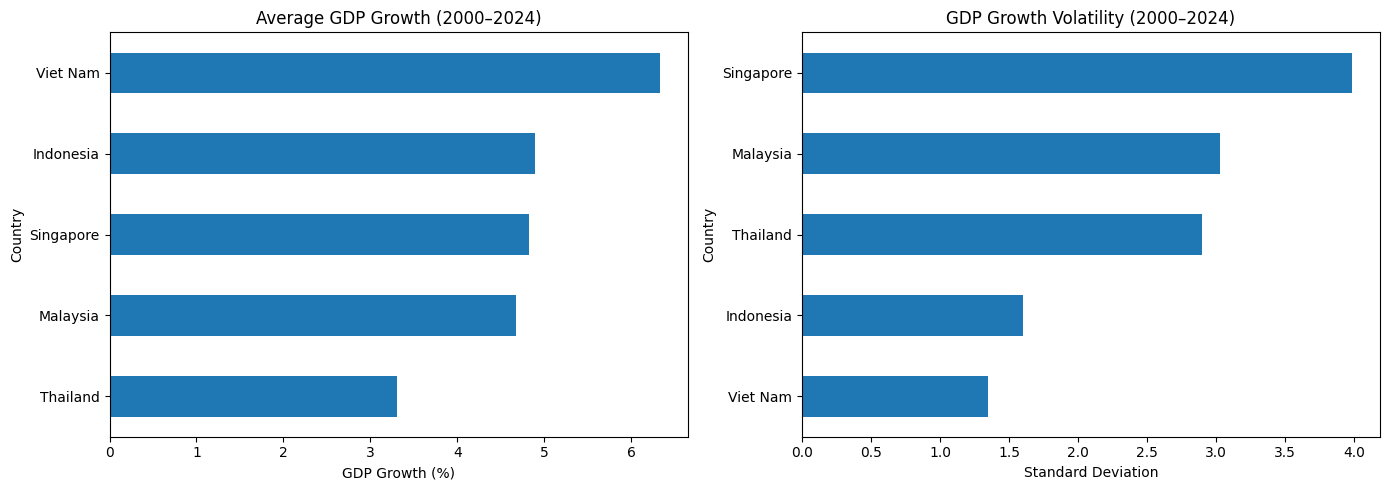

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average GDP growth
gdp_statistics["mean"].sort_values().plot(
    kind="barh",
    ax=axes[0]
)

axes[0].set_title("Average GDP Growth (2000–2024)")
axes[0].set_xlabel("GDP Growth (%)")
axes[0].set_ylabel("Country")

# GDP growth volatility
gdp_statistics["std"].sort_values().plot(
    kind="barh",
    ax=axes[1]
)

axes[1].set_title("GDP Growth Volatility (2000–2024)")
axes[1].set_xlabel("Standard Deviation")
axes[1].set_ylabel("Country")

plt.tight_layout()
plt.show()

In [13]:
inflation_data = raw_data[
    raw_data["Indicator"] == "Inflation"
].copy()

inflation_data = inflation_data.sort_values("Year")

print(inflation_data.head())


       Country Country_Code  Year     Value  Indicator
149  Indonesia          IDN  2000  3.688620  Inflation
174   Malaysia          MYS  2000  1.534740  Inflation
199  Singapore          SGP  2000  1.361624  Inflation
224   Thailand          THA  2000  1.591969  Inflation
249   Viet Nam          VNM  2000 -1.710337  Inflation


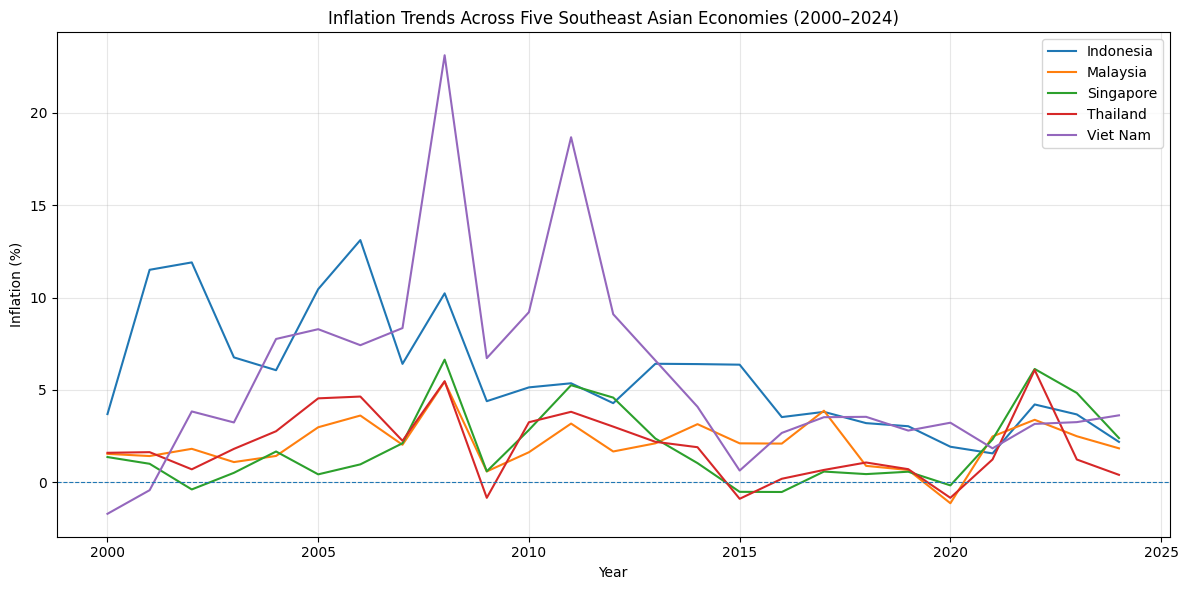

In [14]:
plt.figure(figsize=(12, 6))

for country in inflation_data["Country"].unique():

    country_data = inflation_data[
        inflation_data["Country"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["Value"],
        label=country
    )

plt.title(
    "Inflation Trends Across Five Southeast Asian Economies (2000–2024)"
)

plt.xlabel("Year")
plt.ylabel("Inflation (%)")

plt.axhline(y=0, linestyle="--", linewidth=0.8)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
inflation_statistics = inflation_data.groupby(
    "Country"
)["Value"].agg(
    ["mean", "median", "std", "min", "max"]
)

print(inflation_statistics.round(2))

           mean  median   std   min    max
Country                                   
Indonesia  5.82    5.13  3.25  1.56  13.11
Malaysia   2.09    2.03  1.30 -1.14   5.44
Singapore  1.88    1.03  2.09 -0.53   6.64
Thailand   1.94    1.63  1.90 -0.90   6.08
Viet Nam   5.70    3.62  5.45 -1.71  23.12


In [16]:
# Find the year with the highest inflation for each country

highest_inflation = inflation_data.loc[
    inflation_data.groupby("Country")["Value"].idxmax()
]

print(
    highest_inflation[
        ["Country", "Year", "Value"]
    ].sort_values("Value", ascending=False)
)

       Country  Year      Value
241   Viet Nam  2008  23.115448
143  Indonesia  2006  13.108671
191  Singapore  2008   6.635441
202   Thailand  2022   6.075900
166   Malaysia  2008   5.440782


In [17]:
inflation_2022 = inflation_data[
    inflation_data["Year"] == 2022
][["Country", "Value"]]

print(inflation_2022.sort_values("Value", ascending=False))

       Country     Value
177  Singapore  6.130954
202   Thailand  6.075900
127  Indonesia  4.209465
152   Malaysia  3.378699
227   Viet Nam  3.156507


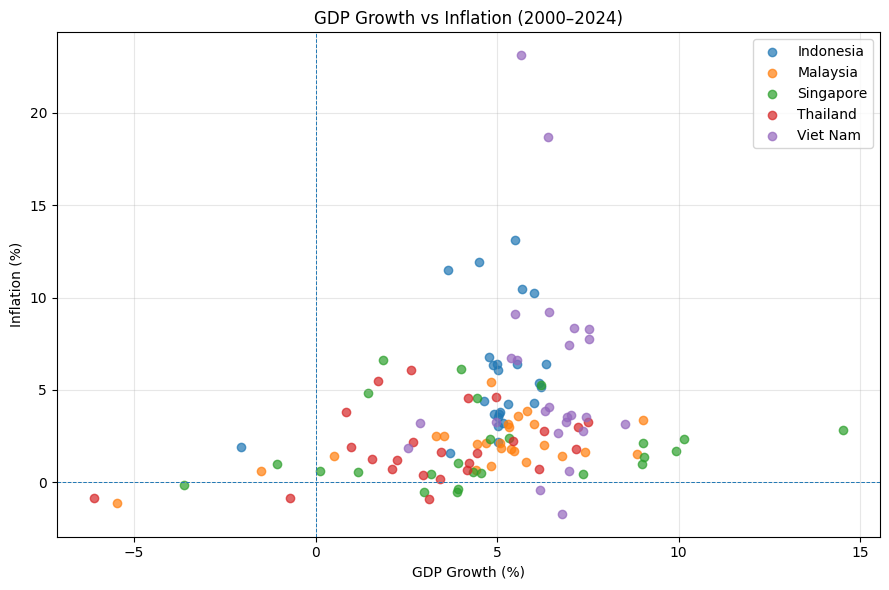

In [18]:
# Combine GDP growth and inflation
macro_combined = pd.merge(
    gdp_data[["Country", "Year", "Value"]].rename(
        columns={"Value": "GDP_Growth"}
    ),
    inflation_data[["Country", "Year", "Value"]].rename(
        columns={"Value": "Inflation"}
    ),
    on=["Country", "Year"],
    how="inner"
)

# Scatter plot
plt.figure(figsize=(9, 6))

for country in macro_combined["Country"].unique():

    country_data = macro_combined[
        macro_combined["Country"] == country
    ]

    plt.scatter(
        country_data["GDP_Growth"],
        country_data["Inflation"],
        label=country,
        alpha=0.7
    )

plt.title("GDP Growth vs Inflation (2000–2024)")
plt.xlabel("GDP Growth (%)")
plt.ylabel("Inflation (%)")
plt.axhline(y=0, linestyle="--", linewidth=0.7)
plt.axvline(x=0, linestyle="--", linewidth=0.7)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
correlation = macro_combined[
    ["GDP_Growth", "Inflation"]
].corr()

print(correlation.round(3))

            GDP_Growth  Inflation
GDP_Growth       1.000      0.229
Inflation        0.229      1.000


In [20]:
# Calculate GDP-inflation correlation for each country

country_correlations = macro_combined.groupby(
    "Country"
).apply(
    lambda group: group["GDP_Growth"].corr(
        group["Inflation"]
    ),
    include_groups=False
)

print(country_correlations.round(3))

Country
Indonesia    0.247
Malaysia     0.521
Singapore    0.122
Thailand     0.316
Viet Nam    -0.010
dtype: float64


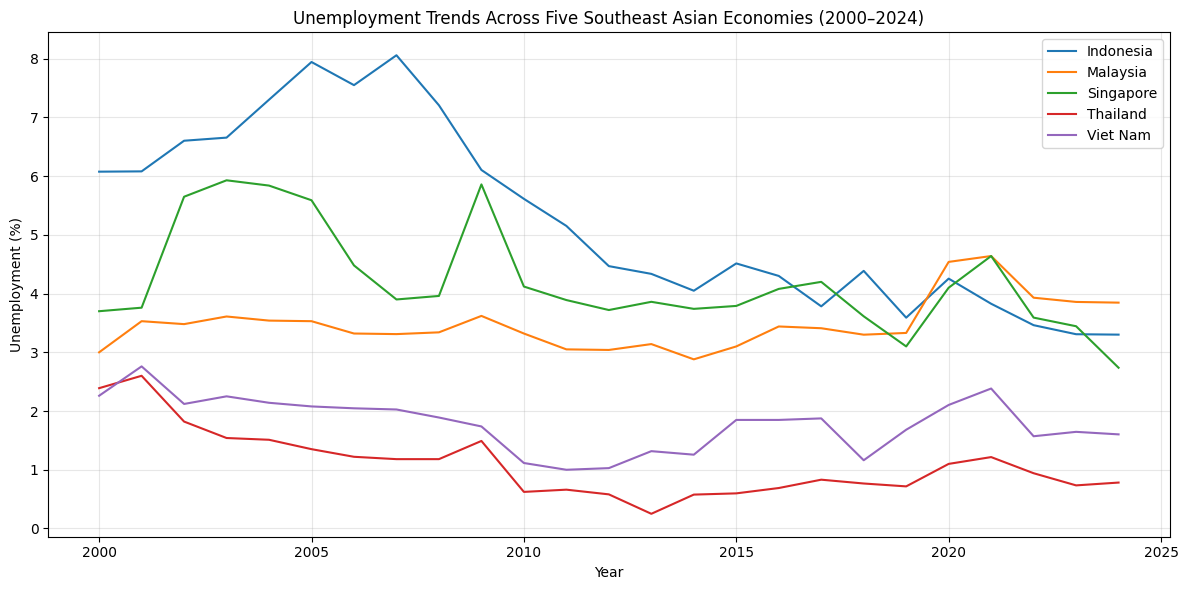

In [21]:
unemployment_data = raw_data[
    raw_data["Indicator"] == "Unemployment"
].copy()

plt.figure(figsize=(12, 6))

for country in unemployment_data["Country"].unique():

    country_data = unemployment_data[
        unemployment_data["Country"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["Value"],
        label=country
    )

plt.title(
    "Unemployment Trends Across Five Southeast Asian Economies (2000–2024)"
)

plt.xlabel("Year")
plt.ylabel("Unemployment (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
unemployment_statistics = unemployment_data.groupby(
    "Country"
)["Value"].agg(
    ["mean", "median", "std", "min", "max"]
)

print(unemployment_statistics.round(2))

           mean  median   std   min   max
Country                                  
Indonesia  5.28    4.51  1.56  3.30  8.06
Malaysia   3.48    3.41  0.43  2.88  4.64
Singapore  4.21    3.90  0.89  2.74  5.93
Thailand   1.09    0.94  0.57  0.25  2.60
Viet Nam   1.79    1.85  0.46  1.00  2.76


In [23]:
exchange_data = raw_data[
    raw_data["Indicator"] == "Exchange_Rate"
].copy()

exchange_data = exchange_data.sort_values("Year")

print(exchange_data.head())

       Country Country_Code  Year         Value      Indicator
399  Indonesia          IDN  2000   8421.775000  Exchange_Rate
424   Malaysia          MYS  2000      3.800000  Exchange_Rate
449  Singapore          SGP  2000      1.723963  Exchange_Rate
474   Thailand          THA  2000     40.111803  Exchange_Rate
499   Viet Nam          VNM  2000  14167.750000  Exchange_Rate


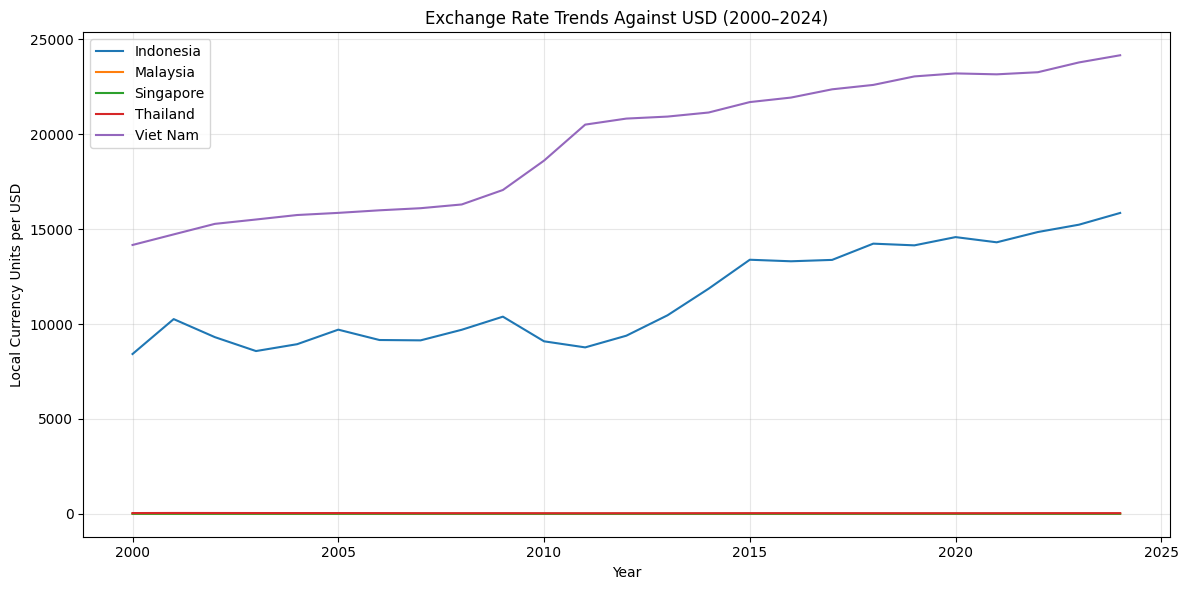

In [25]:
plt.figure(figsize=(12, 6))

for country in exchange_data["Country"].unique():

    country_data = exchange_data[
        exchange_data["Country"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["Value"],
        label=country
    )

plt.title(
    "Exchange Rate Trends Against USD (2000–2024)"
)

plt.xlabel("Year")
plt.ylabel("Local Currency Units per USD")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
print(exchange_data["Country"].unique())

print(
    exchange_data[exchange_data["Country"].str.contains(
        "Vietnam|Viet Nam|Thailand|Indonesia",
        case=False,
        na=False
    )][["Country", "Year", "Value"]].head(20)
)

['Indonesia' 'Malaysia' 'Singapore' 'Thailand' 'Viet Nam']
       Country  Year         Value
399  Indonesia  2000   8421.775000
474   Thailand  2000     40.111803
499   Viet Nam  2000  14167.750000
398  Indonesia  2001  10260.850000
473   Thailand  2001     44.431900
498   Viet Nam  2001  14725.166667
497   Viet Nam  2002  15279.500000
472   Thailand  2002     42.960083
397  Indonesia  2002   9311.191667
471   Thailand  2003     41.484617
496   Viet Nam  2003  15509.583333
396  Indonesia  2003   8577.133333
395  Indonesia  2004   8938.850000
495   Viet Nam  2004  15746.000000
470   Thailand  2004     40.222415
394  Indonesia  2005   9704.741667
469   Thailand  2005     40.220130
494   Viet Nam  2005  15858.916667
393  Indonesia  2006   9159.316667
468   Thailand  2006     37.881983


In [28]:
print(exchange_data.groupby("Country")["Value"].agg(
    ["count", "min", "max"]
))

print("Zero values:", (exchange_data["Value"] == 0).sum())
print("Missing values:", exchange_data["Value"].isna().sum())

           count           min           max
Country                                     
Indonesia     25   8421.775000  15855.448287
Malaysia      25      3.060003      4.576428
Singapore     25      1.249676      1.791723
Thailand      25     30.491733     44.431900
Viet Nam      25  14167.750000  24164.885833
Zero values: 0
Missing values: 0


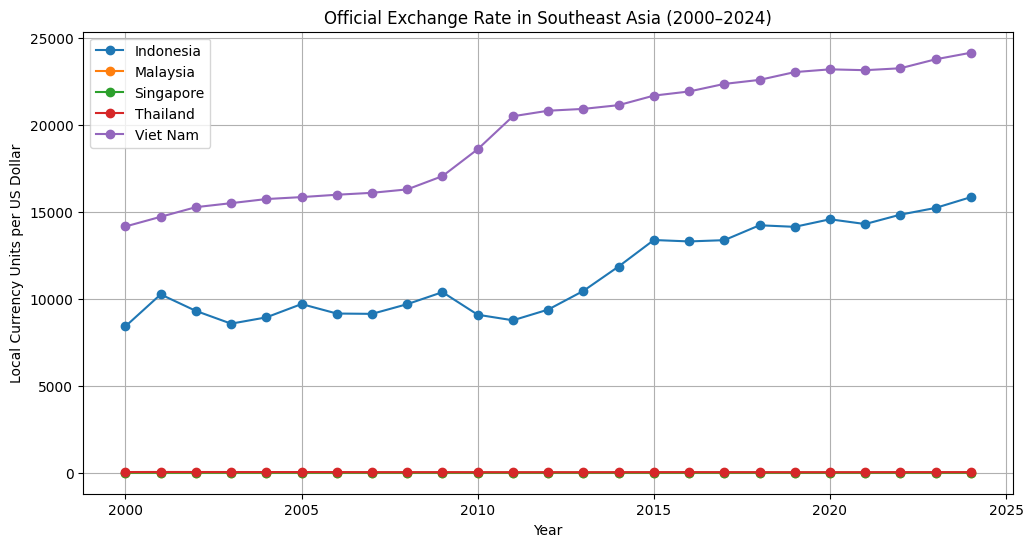

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for country in exchange_data["Country"].unique():
    country_data = exchange_data[
        exchange_data["Country"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["Value"],
        marker="o",
        label=country
    )

plt.title("Official Exchange Rate in Southeast Asia (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Local Currency Units per US Dollar")
plt.legend()
plt.grid(True)
plt.show()

Indonesia 25 8421.775 15855.448286671
Malaysia 25 3.06000301052057 4.5764279106858
Singapore 25 1.2496762037037 1.7917225
Thailand 25 30.4917333333333 44.4319
Viet Nam 25 14167.75 24164.8858333333


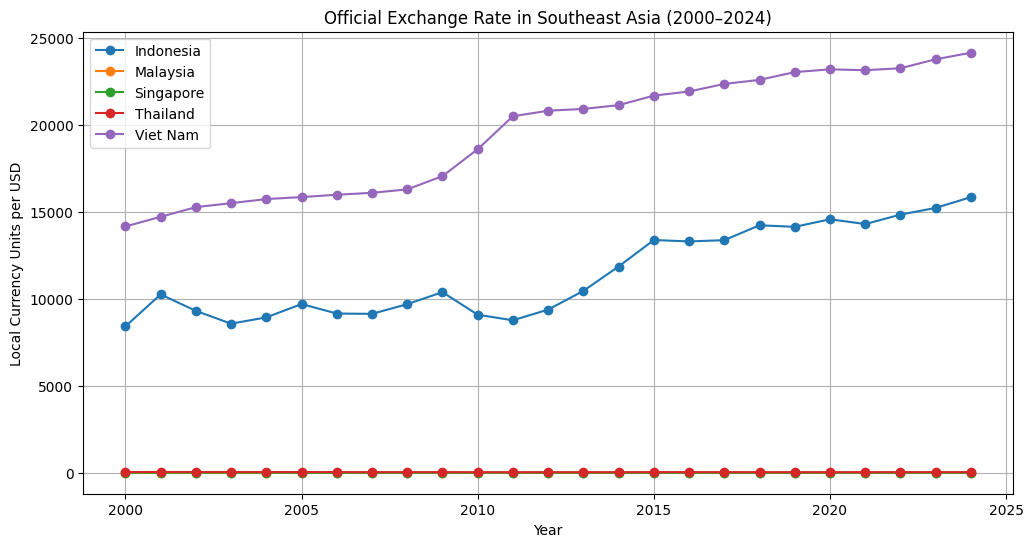

In [34]:
plt.figure(figsize=(12, 6))

for country in exchange_data["Country"].unique():

    country_data = exchange_data[
        exchange_data["Country"] == country
    ].sort_values("Year")

    print(country, len(country_data),
          country_data["Value"].min(),
          country_data["Value"].max())

    plt.plot(
        country_data["Year"],
        country_data["Value"],
        marker="o",
        label=country
    )

plt.title("Official Exchange Rate in Southeast Asia (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Local Currency Units per USD")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
exchange_statistics = exchange_data.groupby(
    "Country"
)["Value"].agg(
    ["mean", "median", "std", "min", "max"]
)

print(exchange_statistics.round(2))

               mean    median      std       min       max
Country                                                   
Indonesia  11458.94  10389.94  2541.00   8421.78  15855.45
Malaysia       3.80      3.80     0.45      3.06      4.58
Singapore      1.46      1.38     0.18      1.25      1.79
Thailand      35.25     34.29     4.10     30.49     44.43
Viet Nam   19521.29  20828.00  3436.02  14167.75  24164.89


In [30]:
fdi_data = raw_data[
    raw_data["Indicator"] == "FDI"
].copy()

fdi_data = fdi_data.sort_values("Year")

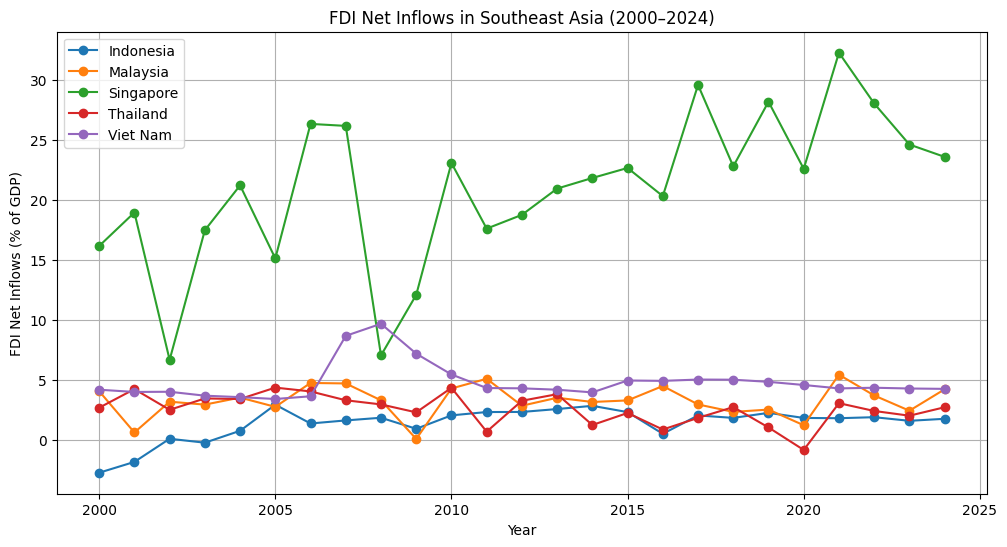

In [31]:
plt.figure(figsize=(12, 6))

for country in fdi_data["Country"].unique():
    country_data = fdi_data[
        fdi_data["Country"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["Value"],
        marker="o",
        label=country
    )

plt.title("FDI Net Inflows in Southeast Asia (2000–2024)")
plt.xlabel("Year")
plt.ylabel("FDI Net Inflows (% of GDP)")
plt.legend()
plt.grid(True)
plt.show()

In [32]:
fdi_statistics = fdi_data.groupby(
    "Country"
)["Value"].agg(
    ["mean", "median", "std", "min", "max"]
)

print(fdi_statistics.round(2))

            mean  median   std   min    max
Country                                    
Indonesia   1.37    1.81  1.36 -2.76   2.92
Malaysia    3.24    3.27  1.30  0.06   5.42
Singapore  20.95   21.82  6.33  6.65  32.26
Thailand    2.57    2.70  1.28 -0.86   4.34
Viet Nam    4.81    4.28  1.52  3.39   9.66


In [33]:
highest_fdi = fdi_data.loc[
    fdi_data.groupby("Country")["Value"].idxmax()
]

lowest_fdi = fdi_data.loc[
    fdi_data.groupby("Country")["Value"].idxmin()
]

print("Highest FDI year:")
print(highest_fdi[["Country", "Year", "Value"]])

print("\nLowest FDI year:")
print(lowest_fdi[["Country", "Year", "Value"]])

Highest FDI year:
       Country  Year      Value
519  Indonesia  2005   2.916115
528   Malaysia  2021   5.416264
553  Singapore  2021  32.262485
594   Thailand  2005   4.339587
616   Viet Nam  2008   9.663039

Lowest FDI year:
       Country  Year     Value
524  Indonesia  2000 -2.757440
540   Malaysia  2009  0.056692
572  Singapore  2002  6.653666
579   Thailand  2020 -0.858310
619   Viet Nam  2005  3.390404


In [35]:
summary = raw_data.pivot_table(
    index="Country",
    columns="Indicator",
    values="Value",
    aggfunc="mean"
)

print(summary.round(2))

Indicator  Exchange_Rate    FDI  GDP_Growth  Inflation  Unemployment
Country                                                             
Indonesia       11458.94   1.37        4.89       5.82          5.28
Malaysia            3.80   3.24        4.68       2.09          3.48
Singapore           1.46  20.95        4.82       1.88          4.21
Thailand           35.25   2.57        3.31       1.94          1.09
Viet Nam        19521.29   4.81        6.33       5.70          1.79


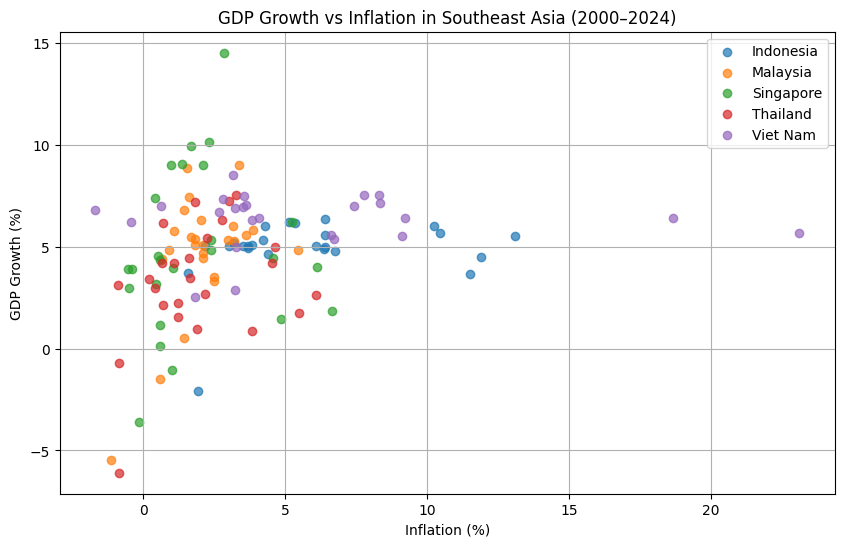

In [36]:
plt.figure(figsize=(10, 6))

for country in raw_data["Country"].unique():

    country_data = raw_data[
        raw_data["Country"] == country
    ].pivot(
        index="Year",
        columns="Indicator",
        values="Value"
    )

    plt.scatter(
        country_data["Inflation"],
        country_data["GDP_Growth"],
        label=country,
        alpha=0.7
    )

plt.title("GDP Growth vs Inflation in Southeast Asia (2000–2024)")
plt.xlabel("Inflation (%)")
plt.ylabel("GDP Growth (%)")
plt.legend()
plt.grid(True)
plt.show()

In [37]:
correlation_results = {}

for country in raw_data["Country"].unique():

    country_data = raw_data[
        raw_data["Country"] == country
    ].pivot(
        index="Year",
        columns="Indicator",
        values="Value"
    )

    correlation_results[country] = (
        country_data["GDP_Growth"].corr(
            country_data["Inflation"]
        )
    )

correlation_df = pd.DataFrame.from_dict(
    correlation_results,
    orient="index",
    columns=["GDP_Inflation_Correlation"]
)

print(correlation_df.round(3))

           GDP_Inflation_Correlation
Indonesia                      0.247
Malaysia                       0.521
Singapore                      0.122
Thailand                       0.316
Viet Nam                      -0.010


In [38]:
shock_years = [2008, 2020, 2022]

shock_data = raw_data[
    raw_data["Year"].isin(shock_years)
].pivot_table(
    index=["Country", "Year"],
    columns="Indicator",
    values="Value"
)

print(shock_data.round(2))

Indicator       Exchange_Rate    FDI  GDP_Growth  Inflation  Unemployment
Country   Year                                                           
Indonesia 2008        9698.96   1.83        6.01      10.23          7.21
          2020       14582.20   1.81       -2.07       1.92          4.26
          2022       14849.85   1.87        5.31       4.21          3.46
Malaysia  2008           3.34   3.28        4.83       5.44          3.34
          2020           4.20   1.20       -5.46      -1.14          4.54
          2022           4.40   3.68        9.03       3.38          3.93
Singapore 2008           1.41   7.02        1.86       6.64          3.96
          2020           1.38  22.58       -3.61      -0.17          4.10
          2022           1.38  28.03        4.01       6.13          3.59
Thailand  2008          33.31   2.94        1.73       5.47          1.18
          2020          31.29  -0.86       -6.09      -0.85          1.10
          2022          35.06   2.39  

In [39]:
gdp_shocks = raw_data[
    (raw_data["Indicator"] == "GDP_Growth") &
    (raw_data["Year"].isin([2008, 2020]))
]

gdp_comparison = gdp_shocks.pivot(
    index="Country",
    columns="Year",
    values="Value"
)

print(gdp_comparison.round(2))

Year       2008  2020
Country              
Indonesia  6.01 -2.07
Malaysia   4.83 -5.46
Singapore  1.86 -3.61
Thailand   1.73 -6.09
Viet Nam   5.66  2.87


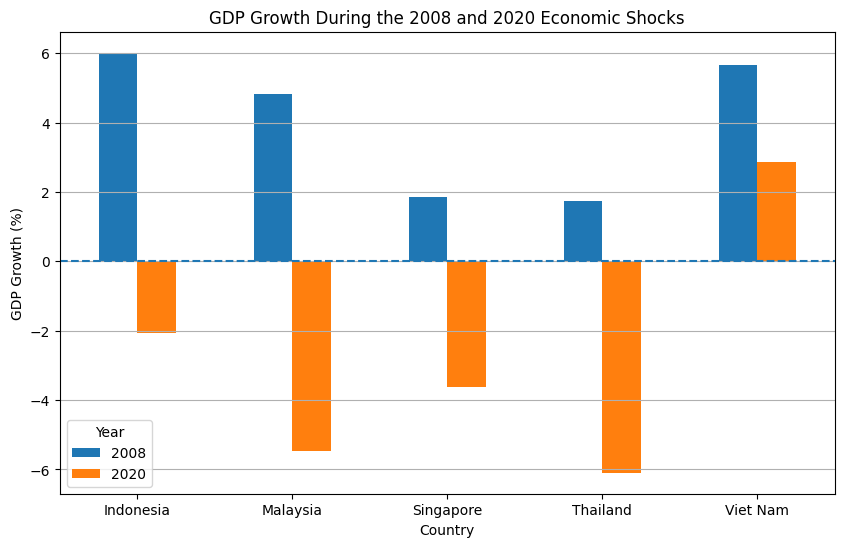

In [40]:
gdp_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("GDP Growth During the 2008 and 2020 Economic Shocks")
plt.xlabel("Country")
plt.ylabel("GDP Growth (%)")
plt.xticks(rotation=0)
plt.axhline(y=0, linestyle="--")
plt.legend(title="Year")
plt.grid(axis="y")
plt.show()

In [41]:
inflation_shocks = raw_data[
    (raw_data["Indicator"] == "Inflation") &
    (raw_data["Year"].isin([2008, 2022]))
]

inflation_comparison = inflation_shocks.pivot(
    index="Country",
    columns="Year",
    values="Value"
)

print(inflation_comparison.round(2))

Year        2008  2022
Country               
Indonesia  10.23  4.21
Malaysia    5.44  3.38
Singapore   6.64  6.13
Thailand    5.47  6.08
Viet Nam   23.12  3.16


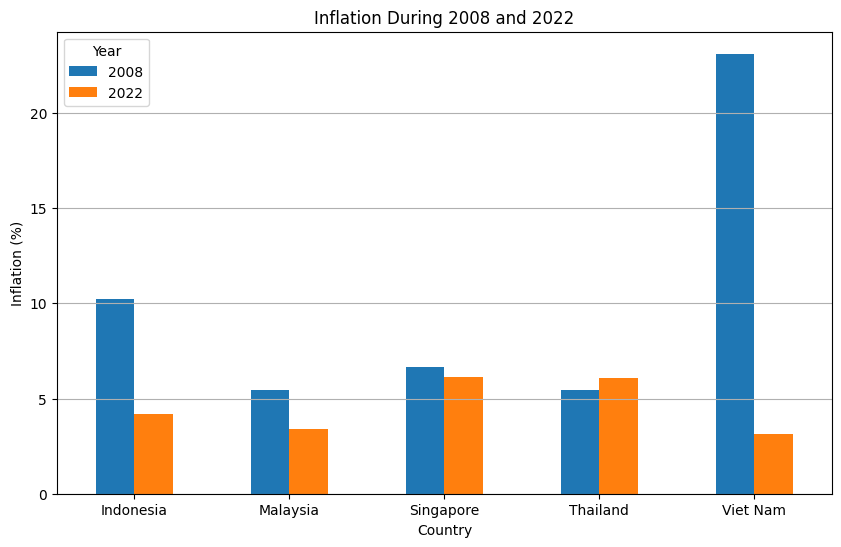

In [42]:
inflation_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Inflation During 2008 and 2022")
plt.xlabel("Country")
plt.ylabel("Inflation (%)")
plt.xticks(rotation=0)
plt.legend(title="Year")
plt.grid(axis="y")
plt.show()

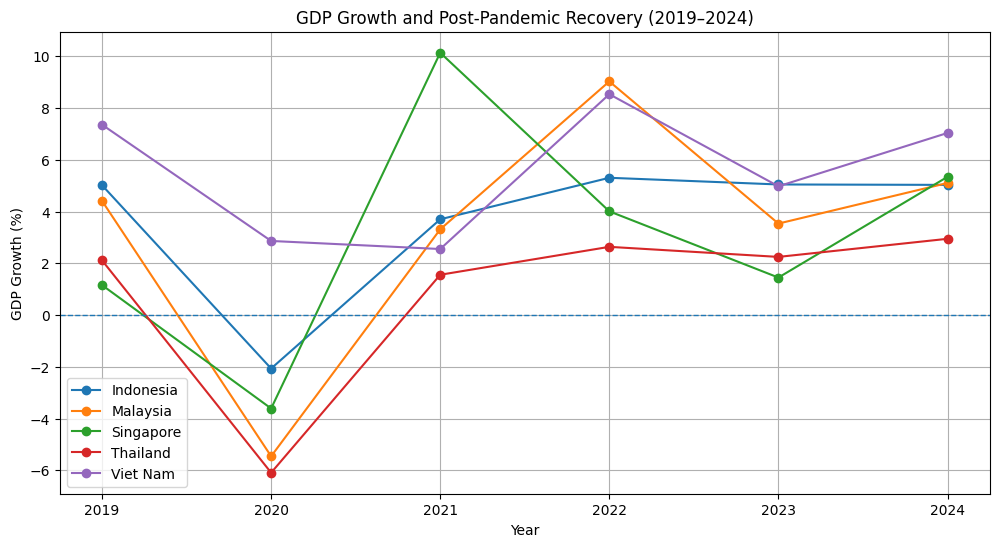

In [43]:
recovery_data = raw_data[
    (raw_data["Indicator"] == "GDP_Growth") &
    (raw_data["Year"].between(2019, 2024))
]

plt.figure(figsize=(12, 6))

for country in recovery_data["Country"].unique():

    country_data = recovery_data[
        recovery_data["Country"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["Value"],
        marker="o",
        label=country
    )

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title("GDP Growth and Post-Pandemic Recovery (2019–2024)")
plt.xlabel("Year")
plt.ylabel("GDP Growth (%)")
plt.legend()
plt.grid(True)
plt.show()

In [44]:
recovery_statistics = recovery_data[
    recovery_data["Year"].between(2021, 2024)
].groupby("Country")["Value"].agg(
    ["mean", "median", "min", "max"]
)

print(recovery_statistics.round(2))

           mean  median   min    max
Country                             
Indonesia  4.77    5.04  3.70   5.31
Malaysia   5.25    4.32  3.32   9.03
Singapore  5.24    4.68  1.45  10.14
Thailand   2.35    2.44  1.56   2.95
Viet Nam   5.78    6.01  2.55   8.54


In [46]:
gdp_data = raw_data[
    raw_data["Indicator"] == "GDP_Growth"
].copy()

gdp_data = gdp_data.rename(
    columns={"Value": "GDP_Growth"}
)

gdp_data = gdp_data[
    gdp_data["Year"].between(2019, 2024)
].sort_values(["Country", "Year"])

gdp_data["GDP_Index"] = 100.0

for country in gdp_data["Country"].unique():

    country_mask = gdp_data["Country"] == country

    country_data = gdp_data.loc[country_mask].copy()

    index_values = [100.0]

    for growth in country_data["GDP_Growth"].iloc[1:]:

        next_index = index_values[-1] * (
            1 + growth / 100
        )

        index_values.append(next_index)

    gdp_data.loc[country_mask, "GDP_Index"] = index_values

print(
    gdp_data[
        ["Country", "Year", "GDP_Growth", "GDP_Index"]
    ].round(2)
)

       Country  Year  GDP_Growth  GDP_Index
5    Indonesia  2019        5.02     100.00
4    Indonesia  2020       -2.07      97.93
3    Indonesia  2021        3.70     101.56
2    Indonesia  2022        5.31     106.95
1    Indonesia  2023        5.05     112.35
0    Indonesia  2024        5.03     118.00
30    Malaysia  2019        4.41     100.00
29    Malaysia  2020       -5.46      94.54
28    Malaysia  2021        3.32      97.68
27    Malaysia  2022        9.03     106.50
26    Malaysia  2023        3.54     110.27
25    Malaysia  2024        5.11     115.90
55   Singapore  2019        1.16     100.00
54   Singapore  2020       -3.61      96.39
53   Singapore  2021       10.14     106.16
52   Singapore  2022        4.01     110.42
51   Singapore  2023        1.45     112.02
50   Singapore  2024        5.34     118.01
80    Thailand  2019        2.11     100.00
79    Thailand  2020       -6.09      93.91
78    Thailand  2021        1.56      95.37
77    Thailand  2022        2.64

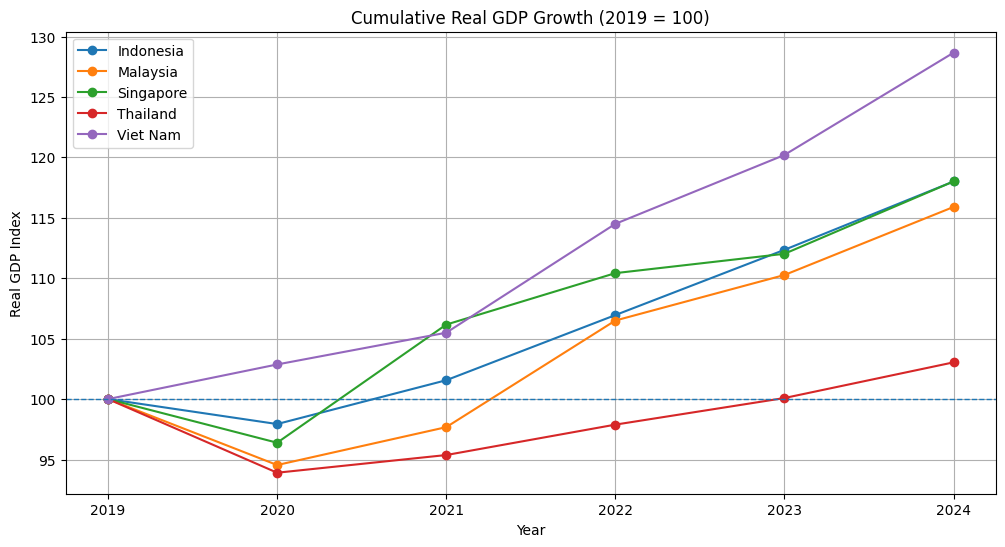

In [47]:
plt.figure(figsize=(12, 6))

for country in gdp_data["Country"].unique():

    country_data = gdp_data[
        gdp_data["Country"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["GDP_Index"],
        marker="o",
        label=country
    )

plt.axhline(y=100, linestyle="--", linewidth=1)

plt.title("Cumulative Real GDP Growth (2019 = 100)")
plt.xlabel("Year")
plt.ylabel("Real GDP Index")
plt.xticks(range(2019, 2025))
plt.legend()
plt.grid(True)
plt.show()

In [48]:
exchange_data = raw_data[
    raw_data["Indicator"] == "Exchange_Rate"
].copy()

exchange_data = exchange_data[
    exchange_data["Year"].between(2019, 2024)
].sort_values(["Country", "Year"])

exchange_data["Exchange_Rate_Index"] = (
    exchange_data.groupby("Country")["Value"]
    .transform(lambda x: (x / x.iloc[0]) * 100)
)

print(
    exchange_data[
        ["Country", "Year", "Value", "Exchange_Rate_Index"]
    ].round(2)
)

       Country  Year     Value  Exchange_Rate_Index
380  Indonesia  2019  14147.67               100.00
379  Indonesia  2020  14582.20               103.07
378  Indonesia  2021  14308.14               101.13
377  Indonesia  2022  14849.85               104.96
376  Indonesia  2023  15236.88               107.70
375  Indonesia  2024  15855.45               112.07
405   Malaysia  2019      4.14               100.00
404   Malaysia  2020      4.20               101.47
403   Malaysia  2021      4.14               100.02
402   Malaysia  2022      4.40               106.24
401   Malaysia  2023      4.56               110.09
400   Malaysia  2024      4.58               110.48
430  Singapore  2019      1.36               100.00
429  Singapore  2020      1.38               101.14
428  Singapore  2021      1.34                98.48
427  Singapore  2022      1.38               101.06
426  Singapore  2023      1.34                98.43
425  Singapore  2024      1.34                97.95
455   Thaila

In [49]:
exchange_comparison = exchange_data[
    exchange_data["Year"] == 2024
][["Country", "Exchange_Rate_Index"]].copy()

exchange_comparison["Change_from_2019"] = (
    exchange_comparison["Exchange_Rate_Index"] - 100
)

print(
    exchange_comparison
    .sort_values("Exchange_Rate_Index", ascending=False)
    .round(2)
)

       Country  Exchange_Rate_Index  Change_from_2019
450   Thailand               113.68             13.68
375  Indonesia               112.07             12.07
400   Malaysia               110.48             10.48
475   Viet Nam               104.84              4.84
425  Singapore                97.95             -2.05


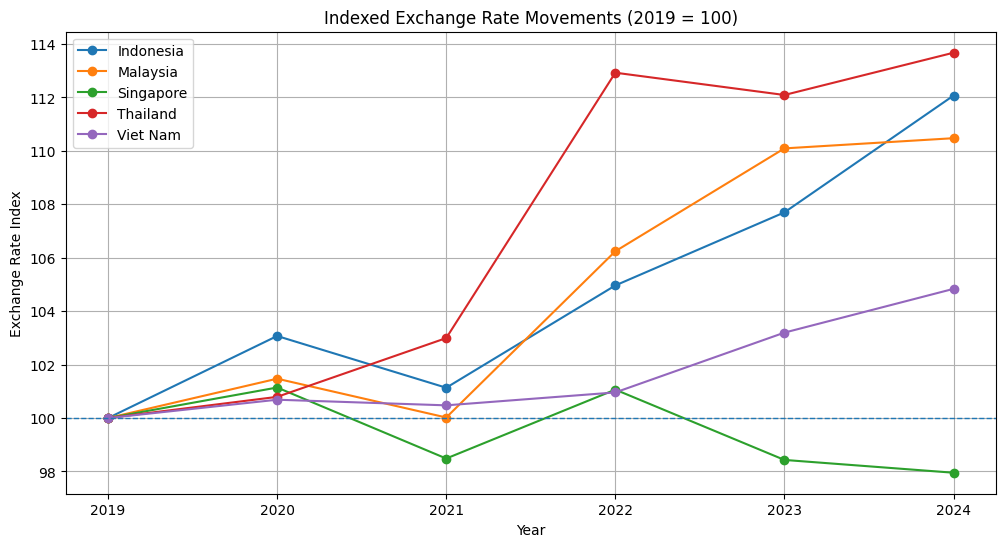

In [50]:
plt.figure(figsize=(12, 6))

for country in exchange_data["Country"].unique():

    country_data = exchange_data[
        exchange_data["Country"] == country
    ].sort_values("Year")

    plt.plot(
        country_data["Year"],
        country_data["Exchange_Rate_Index"],
        marker="o",
        label=country
    )

plt.axhline(y=100, linestyle="--", linewidth=1)

plt.title("Indexed Exchange Rate Movements (2019 = 100)")
plt.xlabel("Year")
plt.ylabel("Exchange Rate Index")
plt.xticks(range(2019, 2025))
plt.legend()
plt.grid(True)
plt.show()

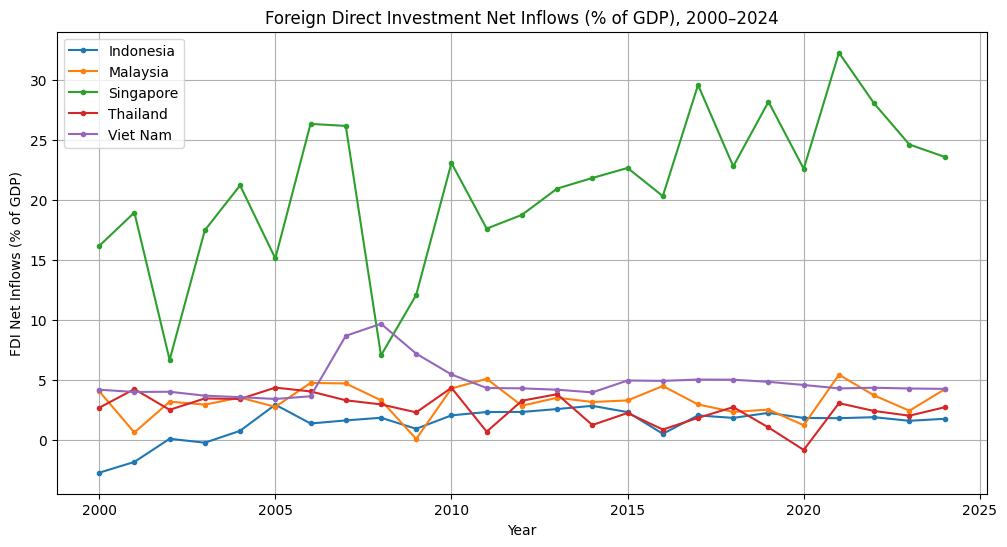

In [51]:
fdi_data = raw_data[
    raw_data["Indicator"] == "FDI"
].copy()

fdi_data = fdi_data.sort_values(["Country", "Year"])

plt.figure(figsize=(12, 6))

for country in fdi_data["Country"].unique():

    country_data = fdi_data[
        fdi_data["Country"] == country
    ]

    plt.plot(
        country_data["Year"],
        country_data["Value"],
        marker="o",
        markersize=3,
        label=country
    )

plt.title("Foreign Direct Investment Net Inflows (% of GDP), 2000–2024")
plt.xlabel("Year")
plt.ylabel("FDI Net Inflows (% of GDP)")
plt.legend()
plt.grid(True)
plt.show()

In [52]:
fdi_summary = (
    fdi_data.groupby("Country")["Value"]
    .agg(["mean", "median", "min", "max", "std"])
    .round(2)
)

print(fdi_summary.sort_values("mean", ascending=False))

            mean  median   min    max   std
Country                                    
Singapore  20.95   21.82  6.65  32.26  6.33
Viet Nam    4.81    4.28  3.39   9.66  1.52
Malaysia    3.24    3.27  0.06   5.42  1.30
Thailand    2.57    2.70 -0.86   4.34  1.28
Indonesia   1.37    1.81 -2.76   2.92  1.36


In [53]:
fdi_2024 = fdi_data[
    fdi_data["Year"] == 2024
][["Country", "Value"]].copy()

print(fdi_2024.sort_values("Value", ascending=False).round(2))

       Country  Value
550  Singapore  23.58
600   Viet Nam   4.23
525   Malaysia   4.20
575   Thailand   2.70
500  Indonesia   1.74


In [54]:
fdi_data["Period"] = fdi_data["Year"].apply(
    lambda year: "Pre-pandemic (2000–2019)"
    if year <= 2019
    else "Pandemic and recovery (2020–2024)"
)

fdi_period_comparison = (
    fdi_data.groupby(["Country", "Period"])["Value"]
    .mean()
    .unstack()
    .round(2)
)

fdi_period_comparison["Difference"] = (
    fdi_period_comparison["Pandemic and recovery (2020–2024)"]
    - fdi_period_comparison["Pre-pandemic (2000–2019)"]
)

print(fdi_period_comparison)

Period     Pandemic and recovery (2020–2024)  Pre-pandemic (2000–2019)  \
Country                                                                  
Indonesia                               1.76                      1.27   
Malaysia                                3.38                      3.20   
Singapore                              26.21                     19.64   
Thailand                                1.85                      2.75   
Viet Nam                                4.33                      4.93   

Period     Difference  
Country                
Indonesia        0.49  
Malaysia         0.18  
Singapore        6.57  
Thailand        -0.90  
Viet Nam        -0.60  


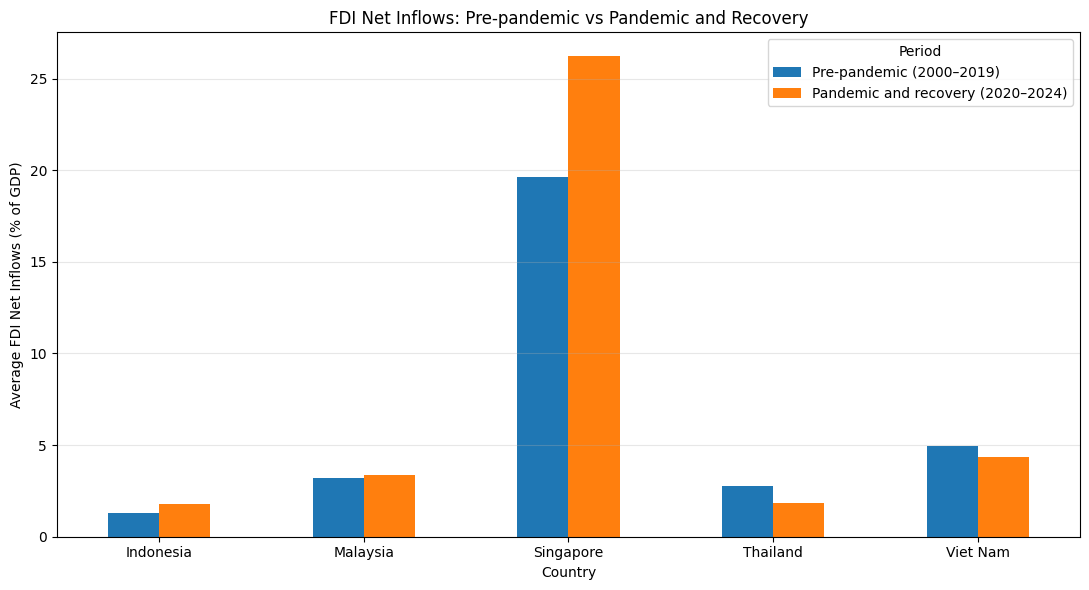

In [55]:
fdi_period_comparison[
    ["Pre-pandemic (2000–2019)",
     "Pandemic and recovery (2020–2024)"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("FDI Net Inflows: Pre-pandemic vs Pandemic and Recovery")
plt.xlabel("Country")
plt.ylabel("Average FDI Net Inflows (% of GDP)")
plt.xticks(rotation=0)
plt.legend(title="Period")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
macro_data = raw_data.pivot_table(
    index=["Country", "Year"],
    columns="Indicator",
    values="Value"
).reset_index()

macro_data.columns.name = None

print(macro_data.head())
print(macro_data.shape)

     Country  Year  Exchange_Rate       FDI  GDP_Growth  Inflation  \
0  Indonesia  2000    8421.775000 -2.757440    4.920068   3.688620   
1  Indonesia  2001   10260.850000 -1.855686    3.643466  11.500116   
2  Indonesia  2002    9311.191667  0.074152    4.499475  11.900120   
3  Indonesia  2003    8577.133333 -0.254256    4.780369   6.757313   
4  Indonesia  2004    8938.850000  0.738244    5.030874   6.064062   

   Unemployment  
0         6.077  
1         6.082  
2         6.604  
3         6.657  
4         7.303  
(125, 7)


In [57]:
correlation_matrix = macro_data[
    [
        "GDP_Growth",
        "Inflation",
        "Unemployment",
        "Exchange_Rate",
        "FDI"
    ]
].corr(method="pearson")

print(correlation_matrix.round(2))

               GDP_Growth  Inflation  Unemployment  Exchange_Rate   FDI
GDP_Growth           1.00       0.23          0.07           0.24  0.12
Inflation            0.23       1.00          0.15           0.42 -0.16
Unemployment         0.07       0.15          1.00          -0.09  0.16
Exchange_Rate        0.24       0.42         -0.09           1.00 -0.29
FDI                  0.12      -0.16          0.16          -0.29  1.00


In [58]:
countries = macro_data["Country"].unique()

indicators = [
    "GDP_Growth",
    "Inflation",
    "Unemployment",
    "Exchange_Rate",
    "FDI"
]

for country in countries:

    country_data = macro_data[
        macro_data["Country"] == country
    ]

    country_corr = country_data[indicators].corr()

    print(f"\n===== {country} =====")
    print(country_corr.round(2))


===== Indonesia =====
               GDP_Growth  Inflation  Unemployment  Exchange_Rate   FDI
GDP_Growth           1.00       0.25          0.22          -0.37  0.15
Inflation            0.25       1.00          0.71          -0.60 -0.17
Unemployment         0.22       0.71          1.00          -0.81 -0.30
Exchange_Rate       -0.37      -0.60         -0.81           1.00  0.32
FDI                  0.15      -0.17         -0.30           0.32  1.00

===== Malaysia =====
               GDP_Growth  Inflation  Unemployment  Exchange_Rate   FDI
GDP_Growth           1.00       0.52         -0.51          -0.13  0.65
Inflation            0.52       1.00         -0.28          -0.16  0.46
Unemployment        -0.51      -0.28          1.00           0.62 -0.11
Exchange_Rate       -0.13      -0.16          0.62           1.00 -0.11
FDI                  0.65       0.46         -0.11          -0.11  1.00

===== Singapore =====
               GDP_Growth  Inflation  Unemployment  Exchange_Rate   

In [59]:
change_data = macro_data.sort_values(
    ["Country", "Year"]
).copy()

change_data["Exchange_Rate_Change"] = (
    change_data.groupby("Country")["Exchange_Rate"]
    .pct_change() * 100
)

change_data["FDI_Change"] = (
    change_data.groupby("Country")["FDI"]
    .diff()
)

print(
    change_data[
        [
            "Country",
            "Year",
            "Exchange_Rate_Change",
            "FDI_Change"
        ]
    ].head(15).round(2)
)

      Country  Year  Exchange_Rate_Change  FDI_Change
0   Indonesia  2000                   NaN         NaN
1   Indonesia  2001                 21.84        0.90
2   Indonesia  2002                 -9.26        1.93
3   Indonesia  2003                 -7.88       -0.33
4   Indonesia  2004                  4.22        0.99
5   Indonesia  2005                  8.57        2.18
6   Indonesia  2006                 -5.62       -1.57
7   Indonesia  2007                 -0.20        0.26
8   Indonesia  2008                  6.10        0.22
9   Indonesia  2009                  7.12       -0.92
10  Indonesia  2010                -12.51        1.12
11  Indonesia  2011                 -3.52        0.28
12  Indonesia  2012                  7.03        0.01
13  Indonesia  2013                 11.45        0.24
14  Indonesia  2014                 13.42        0.27


In [60]:
change_correlations = {}

for country in change_data["Country"].unique():

    country_data = change_data[
        change_data["Country"] == country
    ].dropna(
        subset=["Exchange_Rate_Change", "FDI_Change"]
    )

    correlation = country_data[
        ["Exchange_Rate_Change", "FDI_Change"]
    ].corr().iloc[0, 1]

    change_correlations[country] = correlation

change_corr_df = pd.DataFrame(
    change_correlations.items(),
    columns=["Country", "Exchange_Rate_Change_vs_FDI_Change"]
)

print(
    change_corr_df
    .sort_values(
        "Exchange_Rate_Change_vs_FDI_Change",
        ascending=False
    )
    .round(2)
)

     Country  Exchange_Rate_Change_vs_FDI_Change
3   Thailand                                0.09
2  Singapore                                0.06
0  Indonesia                                0.01
1   Malaysia                               -0.30
4   Viet Nam                               -0.45


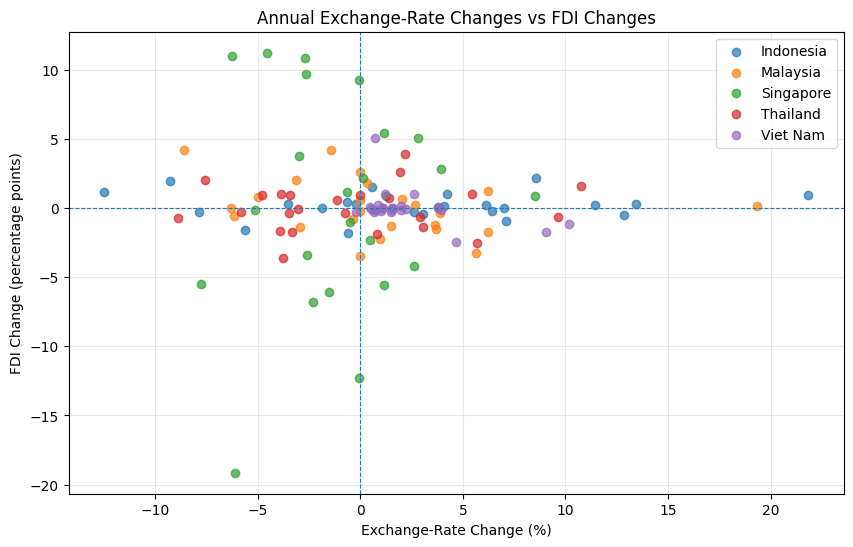

In [61]:
plt.figure(figsize=(10, 6))

for country in change_data["Country"].unique():

    country_data = change_data[
        change_data["Country"] == country
    ]

    plt.scatter(
        country_data["Exchange_Rate_Change"],
        country_data["FDI_Change"],
        label=country,
        alpha=0.7
    )

plt.axhline(y=0, linestyle="--", linewidth=0.8)
plt.axvline(x=0, linestyle="--", linewidth=0.8)

plt.title("Annual Exchange-Rate Changes vs FDI Changes")
plt.xlabel("Exchange-Rate Change (%)")
plt.ylabel("FDI Change (percentage points)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [62]:
fdi_growth_corr = {}

for country in change_data["Country"].unique():

    country_data = change_data[
        change_data["Country"] == country
    ].dropna(subset=["FDI_Change", "GDP_Growth"])

    fdi_growth_corr[country] = country_data[
        ["FDI_Change", "GDP_Growth"]
    ].corr().iloc[0, 1]

print(
    pd.Series(fdi_growth_corr, name="Correlation")
    .sort_values(ascending=False)
    .round(2)
)

Thailand     0.42
Singapore    0.40
Malaysia     0.35
Viet Nam     0.19
Indonesia    0.14
Name: Correlation, dtype: float64


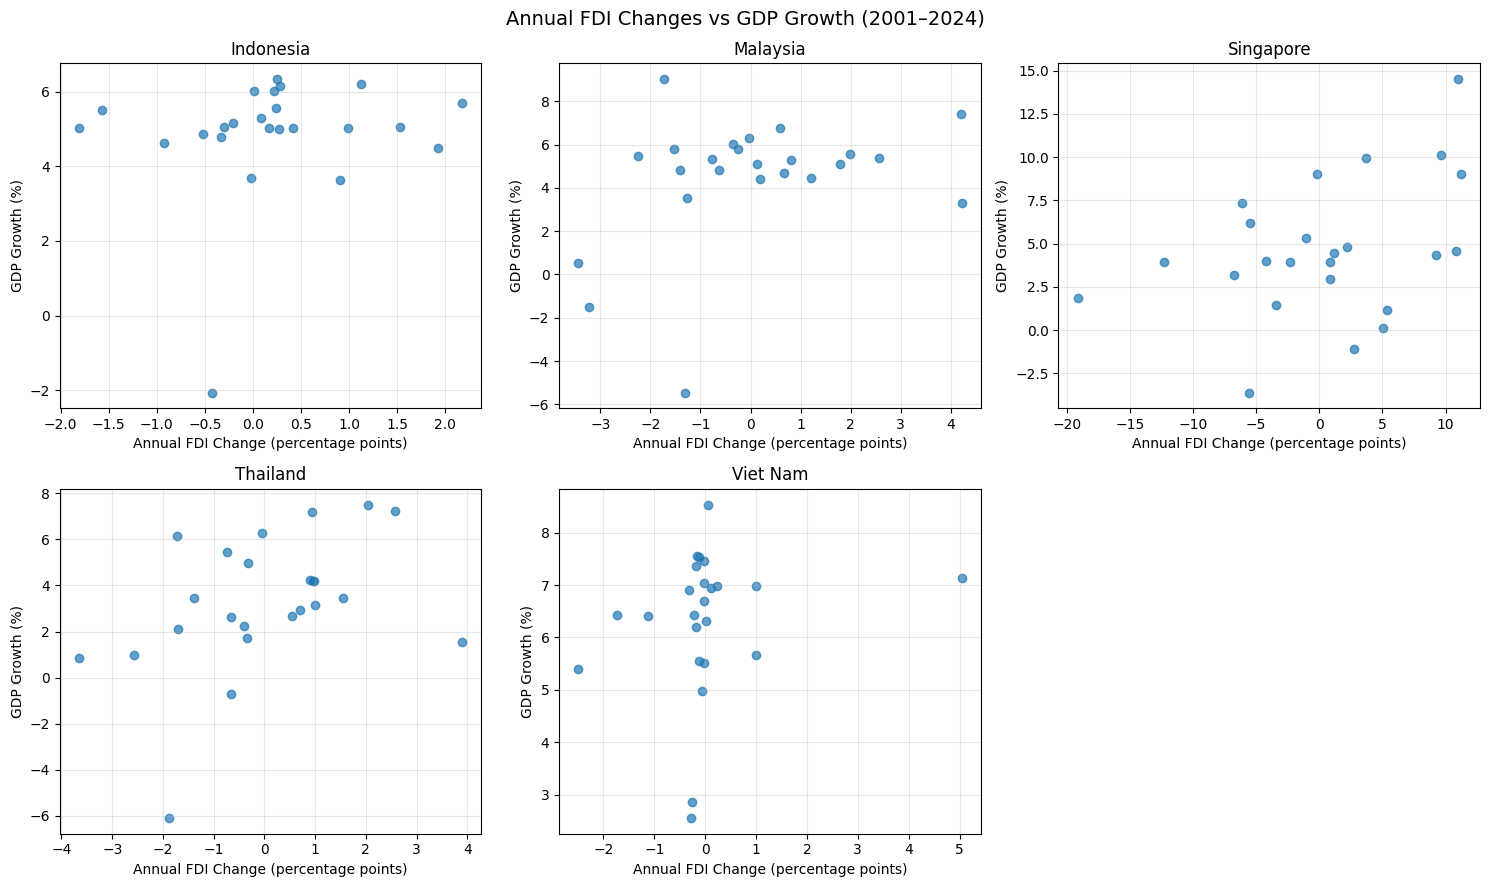

In [63]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, country in enumerate(change_data["Country"].unique()):

    country_data = change_data[
        change_data["Country"] == country
    ].dropna(subset=["FDI_Change", "GDP_Growth"])

    axes[i].scatter(
        country_data["FDI_Change"],
        country_data["GDP_Growth"],
        alpha=0.7
    )

    axes[i].set_title(country)
    axes[i].set_xlabel("Annual FDI Change (percentage points)")
    axes[i].set_ylabel("GDP Growth (%)")
    axes[i].grid(True, alpha=0.3)

axes[-1].axis("off")

plt.suptitle(
    "Annual FDI Changes vs GDP Growth (2001–2024)",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [64]:
indicator_reference = pd.DataFrame({
    "Indicator": [
        "GDP Growth",
        "Inflation",
        "Unemployment",
        "Exchange Rate",
        "FDI"
    ],
    "World Bank Code": [
        "NY.GDP.MKTP.KD.ZG",
        "FP.CPI.TOTL.ZG",
        "SL.UEM.TOTL.ZS",
        "PA.NUS.FCRF",
        "BX.KLT.DINV.WD.GD.ZS"
    ],
    "Measurement": [
        "Annual real GDP growth (%)",
        "Annual consumer price inflation (%)",
        "Unemployment as % of labour force",
        "Local currency units per USD",
        "Net FDI inflows as % of GDP"
    ]
})

display(indicator_reference)

,Indicator,World Bank Code,Measurement
0,GDP Growth,NY.GDP.MKTP.KD.ZG,Annual real GDP growth (%)
1,Inflation,FP.CPI.TOTL.ZG,Annual consumer price inflation (%)
2,Unemployment,SL.UEM.TOTL.ZS,Unemployment as % of labour force
3,Exchange Rate,PA.NUS.FCRF,Local currency units per USD
4,FDI,BX.KLT.DINV.WD.GD.ZS,Net FDI inflows as % of GDP


In [65]:
macro_data.to_csv("asean_macro_cleaned_data.csv", index=False)

indicator_reference.to_csv(
    "asean_indicator_reference.csv",
    index=False
)

print("Files saved successfully!")

Files saved successfully!


In [66]:
import os

folders = ["data", "notebooks", "visuals"]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created!")


Project folders created!


In [67]:
import shutil

shutil.move(
    "asean_macro_raw_data.csv",
    "data/asean_macro_raw_data.csv"
)

shutil.move(
    "asean_macro_cleaned_data.csv",
    "data/asean_macro_cleaned_data.csv"
)

shutil.move(
    "asean_indicator_reference.csv",
    "data/asean_indicator_reference.csv"
)

'data/asean_indicator_reference.csv'